In [1]:
import numpy as np
import pandas as pd
from utils import *
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from collections import defaultdict
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import pairwise_distances

In [2]:
df_spectra_flopp = pd.read_csv('../processed_data/flopp_flopp_e_pivot.csv')
del df_spectra_flopp['Unnamed: 0']

label_table = (
    df_spectra_flopp.
    query('data_source == "flopp"').
    groupby(['polymer']).
    count()['file_name'].
    reset_index().
    reset_index().
    iloc[:,:-1])

label_table_e = (
    df_spectra_flopp.
    query('data_source == "flopp_e"').
    groupby(['polymer']).
    count()['file_name'].
    reset_index().
    reset_index().
    iloc[:,:-1])

label_table = label_table.merge(label_table_e, on='polymer', how='left')
label_table = label_table.drop(np.where(label_table['polymer'] == 'Polyethylene Adipate')[0][0], axis=0)

del label_table['index_x']
del label_table['index_y']
label_table = label_table.reset_index()
label_table.columns = ['label', 'polymer']
polymer_10_more = ['Cotton', 'Polyethylene', 'Polyethylene Terephthalate','Polypropylene', 'Polystyrene']
label_table = label_table.reset_index(drop=True)

label_table_adaptive = label_table.query('polymer in @polymer_10_more')

label_table['label'] = np.arange(label_table.shape[0])
label_table_adaptive['label'] = np.arange(label_table_adaptive.shape[0])

wl_list = np.float64(df_spectra_flopp.columns[3:-1])

df_spectra_flopp_adaptive = df_spectra_flopp.merge(label_table_adaptive)
df_spectra_flopp = df_spectra_flopp.merge(label_table)

y_train = df_spectra_flopp.query('data_source == "flopp"').iloc[:,1].to_numpy()
label_train = df_spectra_flopp.query('data_source == "flopp"').iloc[:,-1].to_numpy()
X_train = df_spectra_flopp.query('data_source == "flopp"').iloc[:,3:-1].to_numpy()
X_train = (X_train - X_train.mean(1)[:, None]) / X_train.std(1)[:, None]

y_test = df_spectra_flopp.query('data_source == "flopp_e"').iloc[:,1].to_numpy()
label_test = df_spectra_flopp.query('data_source == "flopp_e"').iloc[:,-1].to_numpy()
X_test = df_spectra_flopp.query('data_source == "flopp_e"').iloc[:,3:-1].to_numpy()
X_test = (X_test - X_test.mean(1)[:, None]) / X_test.std(1)[:, None]


y_train_a = df_spectra_flopp_adaptive.query('data_source == "flopp"').iloc[:,1].to_numpy()
label_train_a = df_spectra_flopp_adaptive.query('data_source == "flopp"').iloc[:,-1].to_numpy()
X_train_a = df_spectra_flopp_adaptive.query('data_source == "flopp"').iloc[:,3:-1].to_numpy()
X_train_a = (X_train_a - X_train_a.mean(1)[:, None]) / X_train_a.std(1)[:, None]

y_test_a = df_spectra_flopp_adaptive.query('data_source == "flopp_e"').iloc[:,1].to_numpy()
label_test_a = df_spectra_flopp_adaptive.query('data_source == "flopp_e"').iloc[:,-1].to_numpy()
X_test_a = df_spectra_flopp_adaptive.query('data_source == "flopp_e"').iloc[:,3:-1].to_numpy()
X_test_a = (X_test_a - X_test_a.mean(1)[:, None]) / X_test_a.std(1)[:, None]


/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_98361/67368521.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  label_table_adaptive['label'] = np.arange(label_table_adaptive.shape[0])


In [347]:
clf = LogisticRegression(random_state=0)#, C=1, penalty='l1', solver='saga')
clf.fit(X_train, y_train)
clf.score(X_test, y_test)

/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:444: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.91005291005291

In [8]:
clf.predict_proba(X_test[0:1,:])

array([[6.93049219e-06, 9.98858101e-01, 8.33558290e-07, 5.73046722e-07,
        4.65388777e-07, 1.47961901e-06, 2.00306248e-07, 1.32924225e-08,
        1.85320511e-07, 3.98925600e-08, 8.86458423e-04, 9.20823756e-08,
        5.76290150e-06, 2.38864363e-04]])

In [54]:
i = 0
softmaxes = clf.predict_proba(X_test[i:(i+1),:]).flatten()
cumsum = np.sort(softmaxes)[::-1].cumsum(0)[label_test[i]]
cumsum

0.9997445597361353

In [196]:
np.argmax(np.sort(softmaxes)[::-1])

0

In [100]:
def odd(x):
    return 1-np.max(clf.predict_proba(x))

In [67]:
def relu(x):
    return (x > 0)*x

In [248]:
smx.shape

(189, 14)

In [251]:
smx = smx_nn(X_train, X_test, label_train)

In [327]:
# ood is an OOD detector, model is classifier with softmax output

alpha1, alpha2 = .25, .15
delta = 0.1
N = 5
n = X_test.shape[0]
lambda1s = np.linspace(0,1,N) # Usually N ~= 1000
lambda2s = np.linspace(0,1,N)
losses = np.zeros((2,n,N,N)) # 2 losses, n data points, N x N lambdas

for (i,j,k) in [(i,j,k) for i in range(n) for j in range(N) for k in range(N)]:
    #softmaxes = clf.predict_proba(X_test[i:(i+1),:]).flatten()
    softmaxes = smx[i,:]
    softmaxes_sorted = np.sort(softmaxes)[::-1]
    diff = (softmaxes_sorted[0] - softmaxes_sorted[1])
    #cumsum = np.sort(softmaxes)[::-1].cumsum(0)[label_test[i]]
    cumsum = softmaxes[label_test[i]]
    #if odd(X_test[i:(i+1),:]) > lambda1s[j]:
    if diff < lambda1s[j] or np.max(softmaxes) < lambda2s[k]:
        losses[0,i,j,k] = int(np.argmax(softmaxes) == label_test[i])
        continue
    losses[1,i,j,k] = int(np.argmax(softmaxes) != label_test[i])
    
risks = losses.mean(1) # 2 x N x N
risks[1] = risks[1] - alpha2*risks[0]
pval1s = np.exp(-2*n*(relu(alpha1-risks[0])**2)) # Or HB p-value
pval2s = np.exp(-2*n*(relu(alpha2-risks[1])**2)) # Ditto
pvals = np.maximum(pval1s,pval2s)
# Bonferroni can be replaced by sequential graphical test as in LTT paper
valid = np.where(pvals <= delta/(N*N))
lambda_hat = [lambda1s[valid[0]], lambda2s[valid[1]]]

In [328]:
lambda_hat

[array([], dtype=float64), array([], dtype=float64)]

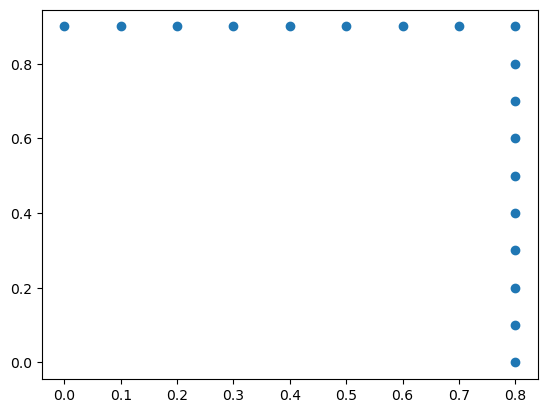

In [324]:
plt.scatter(np.array(lambda_hat)[0,:], np.array(lambda_hat)[1,:])

In [113]:
np.sort(softmaxes)[::-1].cumsum(0).shape#[label_test[i]]

(14,)

In [ ]:
# The following loop can be massively parallelized (and GPU accelerated)
for (i,j,k) in [(i,j,k) for i in range(n) for j in range(N) for k in range(N)]:
    softmaxes = model(X[i].unsqueeze(0)).softmax(1).squeeze() # Care with dims
    cumsum = softmaxes.sort(descending=True)[0].cumsum(0)[Y[i]]
    if odd(X) > lambda1s[j]:
        losses[0,i,j,k] = 1
        continue
    losses[1,i,j,k] = int(cumsum > lambda2s[k])
risks = losses.mean(dim=1) # 2 x N x N
risks[1] = risks[1] - alpha2*risks[0]
pval1s = torch.exp(-2*n*(torch.relu(alpha1-risks[0])**2)) # Or HB p-value
pval2s = torch.exp(-2*n*(torch.relu(alpha2-risks[1])**2)) # Ditto
pvals = torch.maximum(pval1s,pval2s)
# Bonferroni can be replaced by sequential graphical test as in LTT paper
valid = torch.where(pvals <= delta/(N*N))
lambda_hat = [lambda1s[valid[0]], lambda2s[valid[1]]]

In [337]:
from scipy.optimize import brentq
from scipy.stats import binom

In [341]:
smx = smx_nn(X_train, X_test, label_train)
smx.shape

(189, 14)

In [354]:
smx = clf.predict_proba(X_test)
smx.shape

(189, 14)

In [355]:
# Problem setup
n=150 # number of calibration points
alpha = 0.1 # 1-alpha is the desired selective accuracy
delta = 0.1 # delta is the failure rate
lambdas = np.linspace(0,1,5000)

In [356]:
# Split the softmax scores into calibration and validation sets (save the shuffling)
idx = np.array([1] * n + [0] * (smx.shape[0]-n)) > 0
np.random.shuffle(idx)
cal_smx, val_smx = smx[idx,:], smx[~idx,:]
cal_labels, val_labels = label_test[idx], label_test[~idx]
# Yhat, Phat
cal_yhats = np.argmax(cal_smx,axis=1); val_yhats = np.argmax(val_smx,axis=1);
cal_phats = cal_smx.max(axis=1); val_phats = np.max(val_smx,axis=1);

In [357]:
# Define selective risk
def selective_risk(lam): return (cal_yhats[cal_phats >= lam] != cal_labels[cal_phats >= lam]).sum()/(cal_phats >= lam).sum()
def nlambda(lam): return (cal_phats > lam).sum()
lambdas = np.array([lam for lam in lambdas if nlambda(lam) >= 30]) # Make sure there's some data in the top bin.
def invert_for_ub(r,lam): return binom.cdf(selective_risk(lam)*nlambda(lam),nlambda(lam),r)-delta
# Construct upper boud
def selective_risk_ub(lam): return brentq(invert_for_ub,0,0.9999,args=(lam,))
# Scan to choose lamabda hat
for lhat in np.flip(lambdas):
    if selective_risk_ub(lhat-1/lambdas.shape[0]) > alpha: break
# Deploy procedure on test data
predictions_kept = val_phats >= lhat

In [358]:
lhat

0.46509301860372076

In [359]:
# Calculate empirical selective accuracy
empirical_selective_accuracy = (val_yhats[predictions_kept] == val_labels[predictions_kept]).mean()
print(f"The empirical selective accuracy is: {empirical_selective_accuracy}")
false_flags = (val_yhats[~predictions_kept] == val_labels[~predictions_kept]).mean()
print(f"The fraction of false flags is: {false_flags}")
fraction_kept = predictions_kept.mean()
print(f"The fraction of data points kept is: {fraction_kept}")

The empirical selective accuracy is: 0.8947368421052632
The fraction of false flags is: 1.0
The fraction of data points kept is: 0.9743589743589743
